In [ ]:
# Resolve the repository root so data/ and output/ paths work from any working directory
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import os
from pathlib import Path
import seaborn as sns


Reading the NTL Data

In [2]:
ntl = pd.read_csv(
    "Iran_Province_NTL_Annual/Iran_Annual_NTL_Master_2012_2024.csv"
)

ntl.head()

,Area,Type,Year,Annual_Mean,Annual_Sum
0,Yazd,Province,2012,0.242350,37091.363543
1,Sistan and Baluchistan,Province,2012,0.196490,39705.314040
2,Kerman,Province,2012,0.262493,54321.302014
3,Hormozgan,Province,2012,0.390567,30045.879708
4,fars,Province,2012,0.564258,79468.211308


Reading Population data. this data got cleaned before and the name of the province was a problem which I solve as you can see in the data shape

In [3]:
pop = pd.read_excel(
    "Pop/Province_Population_1390_1404.xlsx",
    sheet_name="Province_Long"
)

pop.head()


,Province,Province_EN,Province_Display,Year,Year_Greg,Population
0,آذربایجان شرقی,East Azerbaijan,آذربایجان شرقی (East Azerbaijan),1390,2011,3724620
1,آذربایجان غربی,West Azerbaijan,آذربایجان غربی (West Azerbaijan),1390,2011,3080576
2,اردبیل,Ardabil,اردبیل (Ardabil),1390,2011,1248488
3,اصفهان,Isfahan,اصفهان (Isfahan),1390,2011,4879312
4,البرز,Alborz,البرز (Alborz),1390,2011,2412513


Before every thing I make sure all the name are the same and we could merge the data with no problem

In [4]:
ntl = ntl.copy()

# Standardize province names so they match the population dataset
ntl["Area"] = ntl["Area"].replace({
    "East Azarbaijan": "East Azerbaijan",
    "West Azarbaijan": "West Azerbaijan",
    "Chahar Mahaal and Bakhtiari": "Chaharmahal and Bakhtiari",
    "fars": "Fars",
    "Hamedan": "Hamadan",
    "Sistan and Baluchistan": "Sistan and Baluchestan",
    "Iran (National)": None   # mark national total for removal
})

# Remove the national aggregate row (we only want provinces)
ntl = ntl.dropna(subset=["Area"])

# Check the cleaned province names
print(sorted(ntl["Area"].unique()))


['Alborz', 'Ardabil', 'Bushehr', 'Chaharmahal and Bakhtiari', 'East Azerbaijan', 'Fars', 'Gilan', 'Golestan', 'Hamadan', 'Hormozgan', 'Ilam', 'Isfahan', 'Kerman', 'Kermanshah', 'Khuzestan', 'Kohgiluyeh and Boyer-Ahmad', 'Kurdistan', 'Lorestan', 'Markazi', 'Mazandaran', 'North Khorasan', 'Qazvin', 'Qom', 'Razavi Khorasan', 'Semnan', 'Sistan and Baluchestan', 'South Khorasan', 'Tehran', 'West Azerbaijan', 'Yazd', 'Zanjan']


merging NTL and pop data

In [5]:
# merge بر اساس استان و سال
merged = ntl.merge(
    pop,
    left_on=['Area', 'Year'],
    right_on=['Province_EN', 'Year_Greg'],
    how='left'
)

# چک کنیم merge درست انجام شده
print(merged.head())
print("\nMissing population rows:")
print(merged['Population'].isna().sum())


                     Area      Type  Year_x  Annual_Mean    Annual_Sum  \
0                    Yazd  Province    2012     0.242350  37091.363543   
1  Sistan and Baluchestan  Province    2012     0.196490  39705.314040   
2                  Kerman  Province    2012     0.262493  54321.302014   
3               Hormozgan  Province    2012     0.390567  30045.879708   
4                    Fars  Province    2012     0.564258  79468.211308   

            Province             Province_EN  \
0                یزد                    Yazd   
1  سیستان و بلوچستان  Sistan and Baluchestan   
2              کرمان                  Kerman   
3            هرمزگان               Hormozgan   
4               فارس                    Fars   

                             Province_Display  Year_y  Year_Greg  Population  
0                                  یزد (Yazd)    1391       2012     1086569  
1  سیستان و بلوچستان (Sistan and Baluchestan)    1391       2012     2580705  
2                            

NTL per Capita

In [6]:
# create NTL per capita
merged["NTL_perCapita"] = merged["Annual_Sum"] / merged["Population"]

# keep only province level observations
df = merged[merged["Type"] == "Province"].copy()

# check
print(df.shape)
df.head()


(403, 12)


,Area,Type,Year_x,Annual_Mean,Annual_Sum,Province,Province_EN,Province_Display,Year_y,Year_Greg,Population,NTL_perCapita
0,Yazd,Province,2012,0.242350,37091.363543,یزد,Yazd,یزد (Yazd),1391,2012,1086569,0.034136
1,Sistan and Baluchestan,Province,2012,0.196490,39705.314040,سیستان و بلوچستان,Sistan and Baluchestan,سیستان و بلوچستان (Sistan and Baluchestan),1391,2012,2580705,0.015385
2,Kerman,Province,2012,0.262493,54321.302014,کرمان,Kerman,کرمان (Kerman),1391,2012,2978370,0.018239
3,Hormozgan,Province,2012,0.390567,30045.879708,هرمزگان,Hormozgan,هرمزگان (Hormozgan),1391,2012,1615902,0.018594
4,Fars,Province,2012,0.564258,79468.211308,فارس,Fars,فارس (Fars),1391,2012,4646302,0.017104


ploting the graph bar for the provinces total and percapita NTL in 2013 vs 2024. It is important to notice that we use Annual Sum in this part

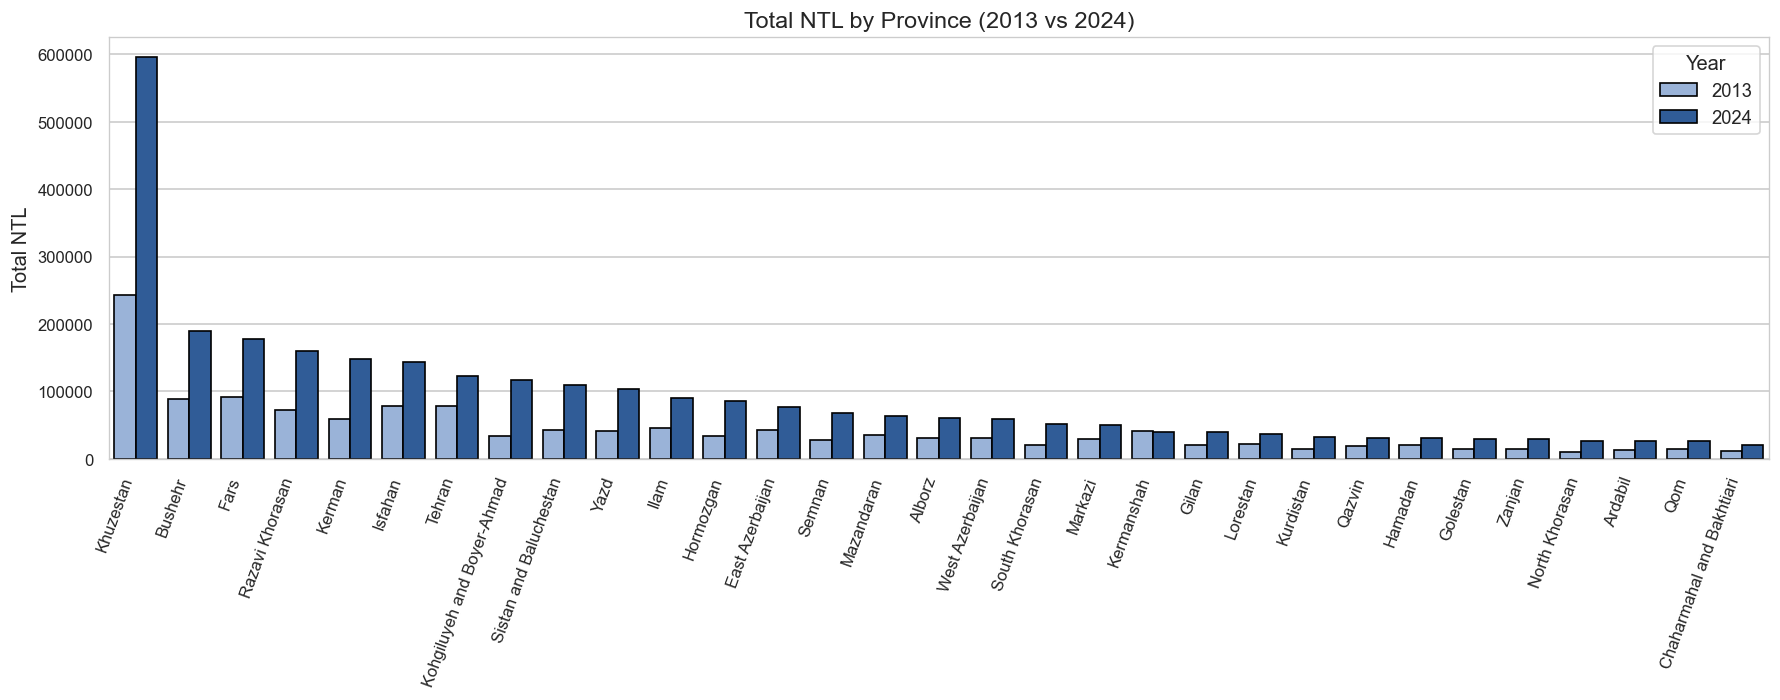

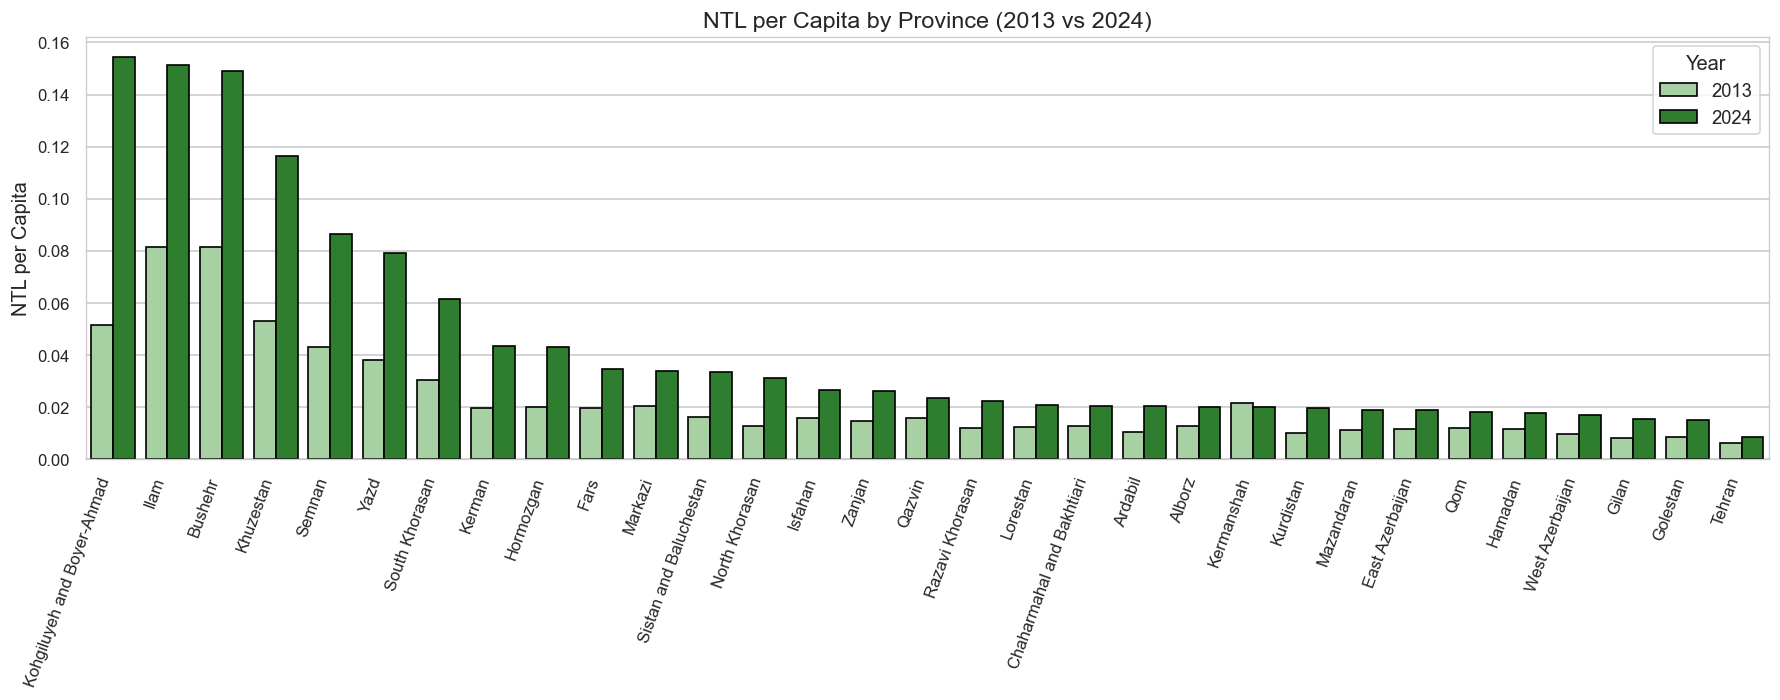

In [8]:
# ---------------------------
# 1) Set professional style
# ---------------------------
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.dpi": 120,
    "axes.linewidth": 0.8,
})


# ---------------------------------
# 2) Build ordering by 2024 values
# ---------------------------------
# select the two years for comparison
df_compare = df[df["Year_x"].isin([2013, 2024])].copy()

# Total NTL sort order
order_total = (
    df_compare[df_compare["Year_x"] == 2024]
    .sort_values("Annual_Sum", ascending=False)["Province_EN"]
)

# Per-capita sort order
order_pc = (
    df_compare[df_compare["Year_x"] == 2024]
    .sort_values("NTL_perCapita", ascending=False)["Province_EN"]
)


# -----------------------------
# 3) Plot 1 — Total NTL
# -----------------------------
plt.figure(figsize=(15, 6))

sns.barplot(
    data=df_compare,
    x="Province_EN",
    y="Annual_Sum",
    hue="Year_x",
    order=order_total,
    palette=["#8FB1E3", "#1F5AA8"],   # light blue vs dark blue
    edgecolor="black"
)

plt.title("Total NTL by Province (2013 vs 2024)")
plt.ylabel("Total NTL")
plt.xlabel("")
plt.xticks(rotation=70, ha="right")

plt.legend(title="Year")
plt.tight_layout()
plt.show()


# -----------------------------
# 4) Plot 2 — NTL per Capita
# -----------------------------
plt.figure(figsize=(15, 6))

sns.barplot(
    data=df_compare,
    x="Province_EN",
    y="NTL_perCapita",
    hue="Year_x",
    order=order_pc,
    palette=["#A1D99B", "#228B22"],   # light green vs forest green
    edgecolor="black"
)

plt.title("NTL per Capita by Province (2013 vs 2024)")
plt.ylabel("NTL per Capita")
plt.xlabel("")
plt.xticks(rotation=70, ha="right")

plt.legend(title="Year")
plt.tight_layout()
plt.show()

ploting the graph bar for the provinces total and percapita NTL in 2013 vs 2024. It is important to notice that we use Annual Mean in this part

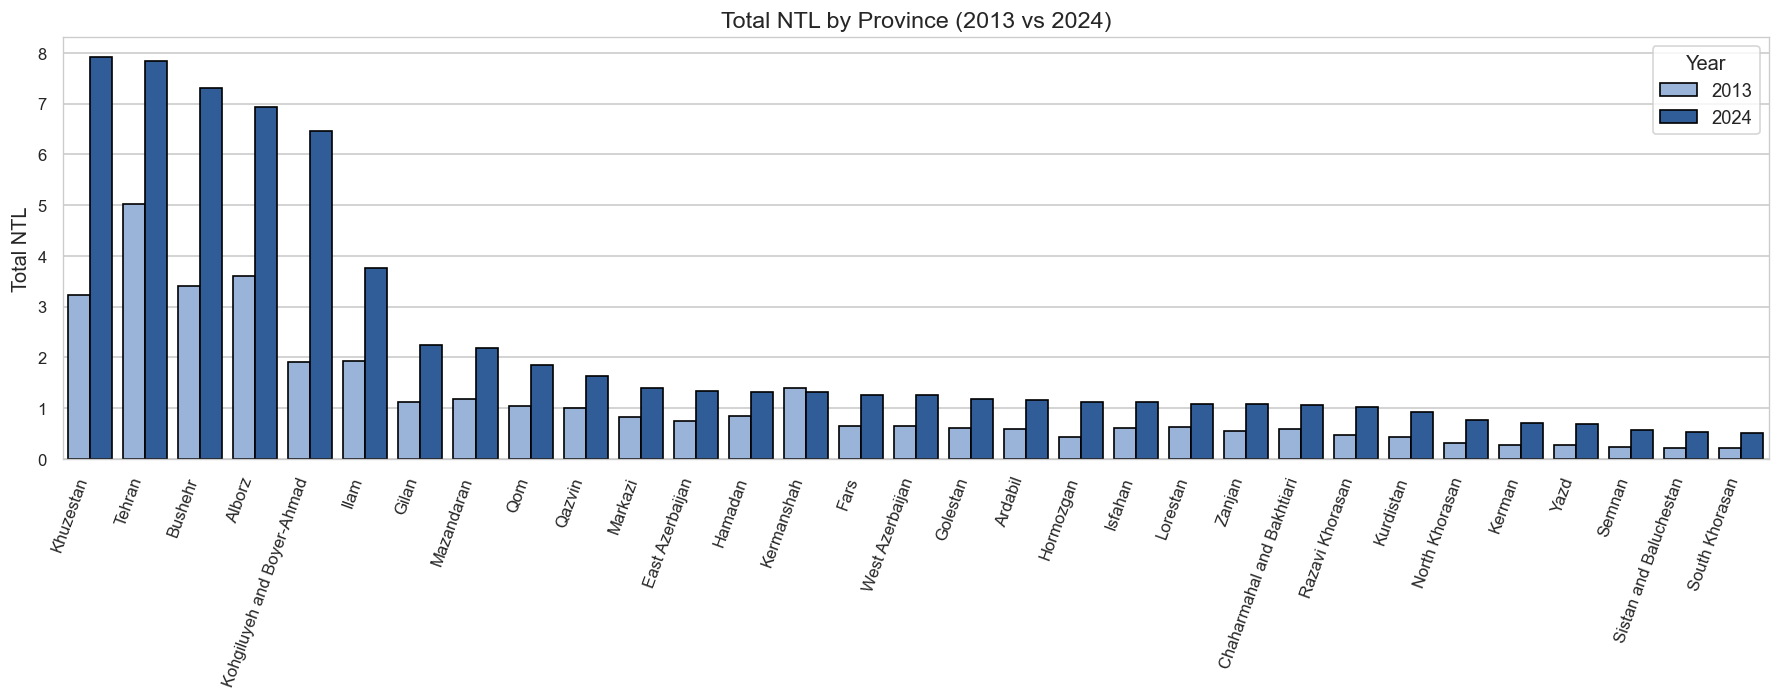

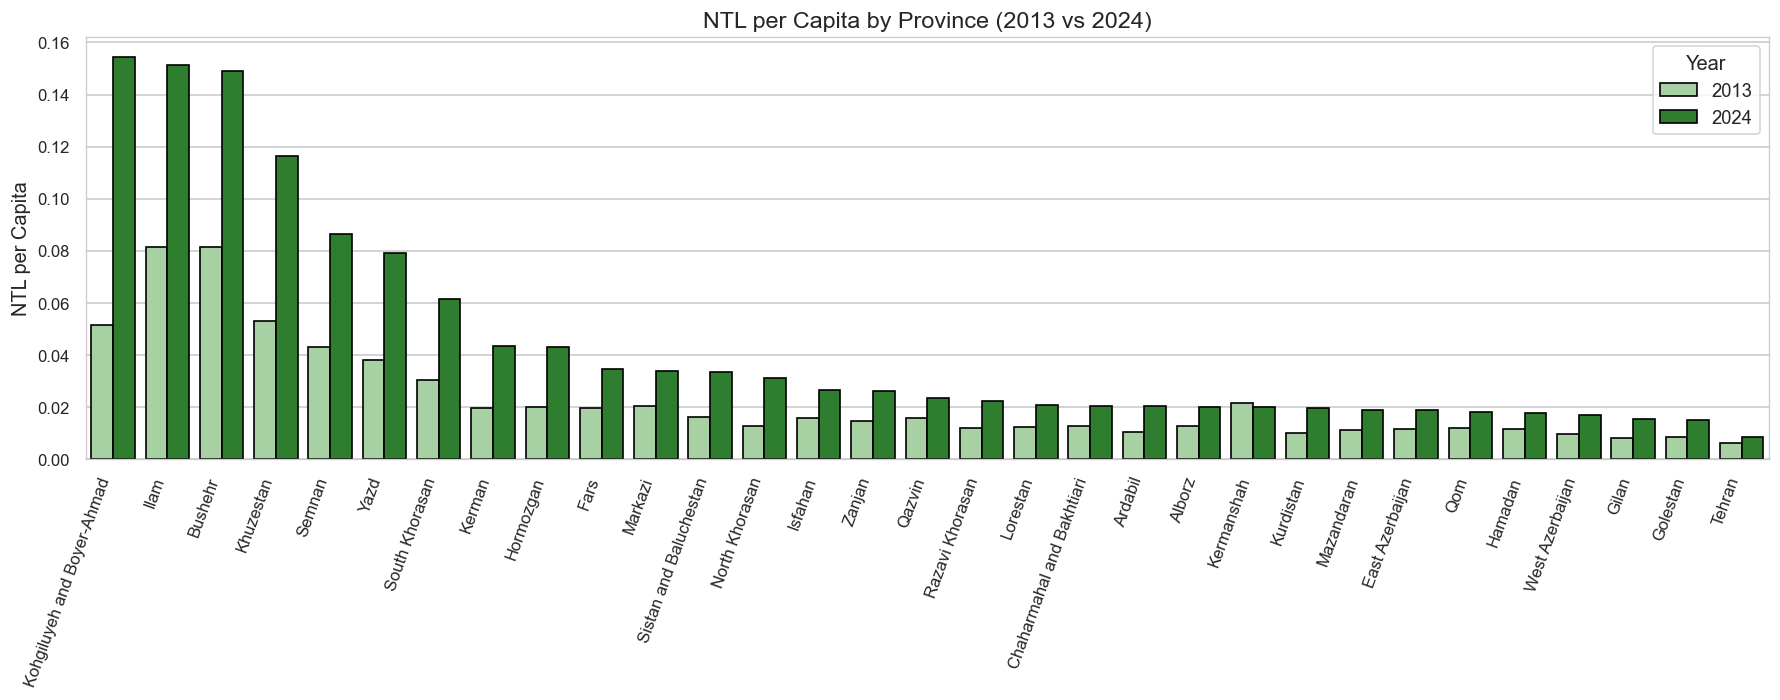

In [9]:
# ---------------------------
# 1) Set professional style
# ---------------------------
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.dpi": 120,
    "axes.linewidth": 0.8,
})


# ---------------------------------
# 2) Build ordering by 2024 values
# ---------------------------------
# select the two years for comparison
df_compare = df[df["Year_x"].isin([2013, 2024])].copy()

# Total NTL sort order
order_total = (
    df_compare[df_compare["Year_x"] == 2024]
    .sort_values("Annual_Mean", ascending=False)["Province_EN"]
)

# Per-capita sort order
order_pc = (
    df_compare[df_compare["Year_x"] == 2024]
    .sort_values("NTL_perCapita", ascending=False)["Province_EN"]
)


# -----------------------------
# 3) Plot 1 — Total NTL
# -----------------------------
plt.figure(figsize=(15, 6))

sns.barplot(
    data=df_compare,
    x="Province_EN",
    y="Annual_Mean",
    hue="Year_x",
    order=order_total,
    palette=["#8FB1E3", "#1F5AA8"],   # light blue vs dark blue
    edgecolor="black"
)

plt.title("Total NTL by Province (2013 vs 2024)")
plt.ylabel("Total NTL")
plt.xlabel("")
plt.xticks(rotation=70, ha="right")

plt.legend(title="Year")
plt.tight_layout()
plt.show()


# -----------------------------
# 4) Plot 2 — NTL per Capita
# -----------------------------
plt.figure(figsize=(15, 6))

sns.barplot(
    data=df_compare,
    x="Province_EN",
    y="NTL_perCapita",
    hue="Year_x",
    order=order_pc,
    palette=["#A1D99B", "#228B22"],   # light green vs forest green
    edgecolor="black"
)

plt.title("NTL per Capita by Province (2013 vs 2024)")
plt.ylabel("NTL per Capita")
plt.xlabel("")
plt.xticks(rotation=70, ha="right")

plt.legend(title="Year")
plt.tight_layout()
plt.show()